In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy scipy pandas matplotlib

# Lecture 21, Weather generators

> A dice-rolling machine for weather, whose odds are set from the observed record

Lectures 18 to 20 corrected or predicted the *output* of a climate model. A **weather generator** (WGEN) works differently. Think of a machine that rolls dice every morning: one roll decides whether it rains, a second decides how much, a third decides how warm it is. The odds on the dice are set from the observed record at one station. Once the odds are set, we can roll for 100 years and get 100 years of daily weather that looks like the record.

Why is this useful? A 30-year record is short. A flood or drought study needs many more years, so that rare cases (a long dry spell followed by a heavy storm) appear. And it is a downscaling tool: if a climate model says wet days will become fewer, we change the odds on the dice and roll again (Section 4).

This lecture follows Lee & Singh (2019), Chapter 6: the background (6.1), the parametric generator (6.2: fitting, simulation, downscaling) and the nearest-neighbour generator (6.3).

By the end of this lecture you should be able to:

- estimate, by hand and in code, the odds of a wet day given yesterday (the transition probabilities),
- say in words what the AR(1) and multivariate AR(1) models do for temperature and radiation,
- fit and run the weather generator for rain, $T_{max}$, $T_{min}$ and solar radiation (SR),
- change its odds for a future climate with the book's logit and Fisher-z rules,
- describe the nearest-neighbour generator.

## Words you need

| Word | Plain meaning | Tiny example |
|---|---|---|
| random number $u$ | a number between 0 and 1 where every value is equally likely, like a spin of a 0 to 1 dial | 0.62 |
| probability | how likely something is, from 0 (never) to 1 (always) | rain on 3 days in 10 gives 0.3 |
| transition probability | the probability of tomorrow's state given today's | if 4 of 8 wet days were followed by a wet day, wet-after-wet is 0.5 |
| limiting probability $P_1$ | the share of all days that are wet in the long run | 0.35 means 35 wet days in 100 |
| spell | a run of days in the same state | wet, wet, wet is a 3-day wet spell |
| autocorrelation | how strongly today's value resembles yesterday's (1 = same, 0 = unrelated) | warm days follow warm days |
| standardise | subtract the usual value for that day and divide by the usual spread, so values become comparable | 36 C on a day that is usually 32 C with spread 2 C gives +2 |
| gamma distribution | a skewed curve for positive amounts: many small values, a few large ones; $\alpha$ sets its shape and $\beta$ its scale (size) | rain on wet days |
| Mahalanobis distance | a distance between two days that accounts for the spread of each variable and how they move together | used in Section 5 |

## Notation

Rule for names in code: book symbol, ASCII, subscripts after underscores, no spaces ($P_{01}$ is `P01`, $\mathbf{A}_1$ is `A1`).

| Book symbol | Meaning | Code / spreadsheet |
|---|---|---|
| $Y_t$, $\varepsilon_t$, $\phi_1$ | AR(1) variable (zero mean), noise $N(0,\sigma_\varepsilon^2)$, coefficient (Eq. 6.2) | `y_s`, `eps`, `phi1` |
| $\mathbf{Y}_t$, $\mathbf{E}_t$ | vectors of the $S$ variables and of the noise (Eq. 6.3) | `Y`, `E` |
| $\mathbf{A}_1$, $\mathbf{B}$, $\mathbf{D}=\mathbf{B}\mathbf{B}^T$ | MAR(1) parameter matrices ($S\times S$), $\mathbf{B}$ lower triangular | `A1`, `B`, `D` |
| $\mathbf{M}_0$, $\mathbf{M}_1$ | lag-zero and lag-one correlation matrices of $\mathbf{Y}_t$ | `M0`, `M1` |
| $X_t$ | occurrence, 1 = wet, 0 = dry | `x`, `X` |
| $P_{ij}$, $\mathbf{P}_T$ | transition probability from state $i$ (day $t-1$) to state $j$ (day $t$), matrix (Eq. 6.18) | `P01`, `P11`, `PT` |
| $N_{ij}$, $N_0$, $N_1$ | counts of transitions, dry days, wet days | `N01`, `N0`, `N1` |
| $P_1$ (and $P_0$) | limiting (wet-day) probability (Eq. 6.20) | `P1`, `P0` |
| $\gamma$ | lag-one autocorrelation of occurrence, $P_{11}-P_{01}$ (Eq. 6.25) | `gam` |
| $\alpha$, $\beta$ | gamma shape and scale of wet-day amount | `alpha`, `beta` |
| $\hat\mu_s(d \mid x_t)$, $\hat\sigma_s(d \mid x_t)$ | mean and sd of variable $s$ on day $d$, given wet or dry; $s=1,2,3$ is $T_{max}$, $T_{min}$, SR | `mu_raw`, `sd_raw` (fits `mu_fit`, `sd_fit`) |
| $\bar u$, $C$, $T$ | cosine fit $u_d=\bar u+C\cos[0.0172(d-T)]$ (Eq. 6.21) | `u_bar`, `C_amp`, `T_off` |
| $y_t^s$, $Z_t^s$ | standardised and back-standardised value (Eqs. 6.22, 6.23) | `y`, `Z` |
| superscripts O, C, F | observation, control run, future scenario | suffix `_O`, `_C`, `_F`; `_adj` |
| $b$, $n_{yr}$, $K$, $D_j$, $\mathbf{C}$ | window width, years, neighbours, Mahalanobis distance, covariance (Eq. 6.34) | `b`, `n_yr`, `K`, `D_j`, `Cinv` |

Two points where the book's convention is worth knowing. The transition probability is indexed **previous state first**: $P_{01}$ is dry yesterday, wet today. The book's $\beta$ is the **scale** and $\alpha$ the shape of the gamma distribution.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gamma as gamma_dist

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

BASE = "data/downscaling/lec21/"
URL = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec21/"
try:
    obs = pd.read_csv(BASE + "obs_daily_synthetic.csv")
except FileNotFoundError:                      # e.g. on Colab without the repository
    obs = pd.read_csv(URL + "obs_daily_synthetic.csv")

# SYNTHETIC "observed" record: 30 years x 365 days of rain, Tmax, Tmin, SR
month, doy = obs["month"].to_numpy(), obs["doy"].to_numpy()
rain = obs["rain_mm"].to_numpy()
x = (rain >= 0.1).astype(int)                  # X_t: wet day = at least 0.1 mm
z = obs[["tmax_c", "tmin_c", "srad_mjm2"]].to_numpy().T   # z[s, t], s = 0, 1, 2 for Tmax, Tmin, SR
n, S, n_yr = len(x), 3, 30
print(f"{n} days = {n_yr} years; wet-day fraction {x.mean():.3f}; mean annual rain {rain.sum()/n_yr:.0f} mm")

10950 days = 30 years; wet-day fraction 0.221; mean annual rain 1007 mm


## 6.1 Mathematical background

### 6.1.1 Autoregressive models

*Idea:* temperature today is close to temperature yesterday, plus a random nudge.

The autoregressive model of order $p$, AR($p$), for a series $Y_t$ with zero mean is

$$Y_t=\sum_{j=1}^{p}\phi_j\,Y_{t-j}+\varepsilon_t,\qquad \varepsilon_t\sim N(0,\sigma_\varepsilon^2)\qquad(6.1)$$

where $\varepsilon_t$ is independent random noise from a bell-shaped (normal) distribution with mean 0 and variance $\sigma_\varepsilon^2$. The simple case, AR(1), keeps only yesterday:

$$Y_t=\phi_1\,Y_{t-1}+\varepsilon_t\qquad(6.2)$$

Example: if yesterday's $Y$ is $+2$ C, $\phi_1=0.6$ and the nudge is $-0.5$ C, today's $Y=0.6(2)-0.5=+0.7$ C. The model assumes no long-term trend and no daily or yearly cycle, and a normal (bell-shaped) series, so a skewed variable is first transformed by a logarithm or a power.

### 6.1.2 Multivariate autoregressive model

*Idea:* Tmax, Tmin and solar radiation each remember their own yesterday and move together on the same day. The multivariate model, MAR(1), does AR(1) for all $S$ variables at once ($S=3$ here); bold letters are lists or tables of numbers.

**Model.** With $\mathbf{Y}_t=[Y_t^1,\dots,Y_t^S]^T$ and noise $\mathbf{E}_t=[\varepsilon_t^1,\dots,\varepsilon_t^S]^T$,

$$\mathbf{Y}_t=\mathbf{A}_1\,\mathbf{Y}_{t-1}+\mathbf{B}\,\mathbf{E}_t\qquad(6.3)$$

where $\mathbf{A}_1$ and $\mathbf{B}$ are $S\times S$ tables of parameters. Written out, each variable today is a weighted sum of all variables yesterday ($\mathbf{A}_1$, entries $a_{ij}$) plus a mix of the noises ($\mathbf{B}$, entries $b_{ij}$) (6.4).

**Parameter estimation.** Multiply (6.3) by $\mathbf{Y}_t^T$ and by $\mathbf{Y}_{t-1}^T$ and take averages (Matalas, 1967); the noise is independent of the past, so those terms vanish (6.5 to 6.8). The result is

$$\mathbf{A}_1=\mathbf{M}_1\mathbf{M}_0^{-1}\quad(6.9),\qquad \mathbf{B}\mathbf{B}^T=\mathbf{M}_0-\mathbf{A}_1\mathbf{M}_1^T\quad(6.10)$$

where $\mathbf{M}_0=[\mathrm{corr}(y_t^i,y_t^j)]$ is the table of correlations between the variables on the same day and $\mathbf{M}_1=[\mathrm{corr}(y_t^i,y_{t-1}^j)]$ the table of correlations between today and yesterday. They are estimated from the data, using $n-1$ day-pairs because each pair needs a yesterday (6.11):

$$\hat{\mathbf{M}}_0=\tfrac{1}{n-1}\textstyle\sum_{t=2}^{n}\mathbf{Y}_t\mathbf{Y}_t^T,\qquad \hat{\mathbf{M}}_1=\tfrac{1}{n-1}\textstyle\sum_{t=2}^{n}\mathbf{Y}_t\mathbf{Y}_{t-1}^T$$

**The noise matrix $\mathbf{B}$.** Only the product $\mathbf{D}=\mathbf{B}\mathbf{B}^T$ is known, so $\mathbf{B}$ is chosen lower triangular (zeros above the diagonal, $b_{ij}=0$ for $i<j$, 6.12), which can be solved one entry at a time (the Cholesky factor): $b_{11}=\sqrt{d_{11}}$, $b_{i1}=d_{i1}/b_{11}$ (6.13), $b_{ii}=[d_{ii}-(b_{i1}^2+\dots+b_{i,i-1}^2)]^{1/2}$ (6.14) and $b_{ji}=[d_{ji}-(b_{j1}b_{i1}+\dots+b_{j,i-1}b_{i,i-1})]/b_{ii}$ for $j>i$ (6.15), giving the table in (6.16). The code does this with one command. For a single variable ($S=1$) the formulas reduce to $\phi_1=M_1/M_0$ and $B=\sqrt{M_0-\phi_1M_1}$, the AR(1) of (6.2).

### 6.1.3 Markov chain

*Idea:* whether tomorrow is wet depends mainly on whether today is wet, and not on earlier days.

A Markov chain is a sequence in which the next state depends only on the present state. Rain occurrence has two states, $X_t=1$ (wet) and $0$ (dry), so

$$\Pr(X_t=1\,|\,X_{t-1}=a_{t-1},\dots,X_1=a_1)=\Pr(X_t=1\,|\,X_{t-1}=a_{t-1})\qquad(6.17)$$

The transition probabilities, $P_{ij}=\Pr(X_t=j\,|\,X_{t-1}=i)$ ("yesterday $i$, today $j$"), form the transition probability matrix

$$\mathbf{P}_T=\begin{bmatrix}P_{00}&P_{01}\\P_{10}&P_{11}\end{bmatrix},\qquad P_{00}=1-P_{01},\;P_{10}=1-P_{11}\qquad(6.18)$$

They are estimated by counting the events that meet the condition, with $N(\cdot)$ the number of such events:

$$P_{01}=\frac{N(X_t=1,X_{t-1}=0)}{N(X_{t-1}=0)}=\frac{N_{01}}{N_0},\qquad P_{11}=\frac{N_{11}}{N_1}\qquad(6.19)$$

where $N_0$, $N_1$ count the dry and wet days that have a day after them (see the note at the end). Without conditioning on yesterday, the long-run (limiting) probability of a wet day, $\mathbf{P}_L=[P_0,P_1]^T$, follows from $\mathbf{P}_L=\mathbf{P}_T\mathbf{P}_L$:

$$P_1=\frac{P_{01}}{P_{10}+P_{01}}=\frac{P_{01}}{1-P_{11}+P_{01}},\qquad P_0=1-P_1\qquad(6.20)$$

*Gloss:* a wet spell ends each day with probability $P_{10}$, so the mean wet spell is $1/P_{10}$ days and the mean dry spell is $1/P_{01}$ days (if rain stops with probability 0.5 each day, spells last 2 days on average). *For hydrology:* rain comes in spells, and the Markov chain captures that persistence, which decides droughts and wet runs.

## Worked example (by hand)

*Same problem type and step order as Examples 6.1 (estimate the transition matrix) and 6.2 (simulate occurrence) of the book, with our own numbers; the spell lengths in (c) are our addition.*

**Problem.** A 20-day wet/dry record, $X_t$ ($1$ = wet), is

`1 1 1 0 0 0 1 1 0 0 0 0 1 1 0 1 0 0 0 0`

(a) Count the transitions and estimate $\mathbf{P}_T$. (b) Find $P_1$. (c) Find the mean wet and dry spell lengths. (d) Simulate days 1 to 3 with $u=0.62,\;0.18,\;0.71$.

**(a) Counts.** *Why:* the odds are estimated by counting how often each kind of day follows each kind. Wet days $N_1=8$ (days 1, 2, 3, 7, 8, 13, 14, 16), dry days $N_0=12$. Going through the 19 consecutive pairs $(X_{t-1},X_t)$:

- wet to wet: days 1-2, 2-3, 7-8, 13-14, so $N_{11}=4$
- wet to dry: 3-4, 8-9, 14-15, 16-17, so $N_{10}=4$
- dry to wet: 6-7, 12-13, 15-16, so $N_{01}=3$
- dry to dry: 4-5, 5-6, 9-10, 10-11, 11-12, 17-18, 18-19, 19-20, so $N_{00}=8$

Check: $4+4+3+8=19=n-1$ (20 days make 19 pairs).

*Divisors. Why:* a probability is "times it happened" divided by "times it could have happened". A day can only be followed by something if it is not the last day. Every wet day has a following day (day 20 is dry), so the wet divisor is $N_1=8$. Day 20 is dry and has no successor, so the dry divisor is $N_0-1=11$ (check: $N_{01}+N_{00}=3+8=11$).

$$P_{11}=\frac{N_{11}}{8}=\frac{4}{8}=0.500,\quad P_{10}=1-0.500=0.500$$

$$P_{01}=\frac{N_{01}}{11}=\frac{3}{11}=0.273,\quad P_{00}=1-0.273=0.727$$

**(b) Limiting probability** (6.20). *Why:* it tells the share of wet days the chain produces in the long run, and the first simulated day needs it because it has no yesterday.

$$P_1=\frac{P_{01}}{1-P_{11}+P_{01}}=\frac{0.2727}{1-0.500+0.2727}=\frac{0.2727}{0.7727}=0.353,\qquad P_0=0.647$$

Check: the chain must keep this share from day to day, $P_{11}P_1+P_{01}P_0=0.500(0.353)+0.2727(0.647)=0.1765+0.1765=0.353$. The share in the record, $N_1/n=8/20=0.40$, differs because 20 days is short.

**(c) Spells.** *Why:* spell lengths tell how long rain or dry periods last. Mean wet spell $=1/P_{10}=1/0.500=2.0$ days; mean dry spell $=1/P_{01}=1/0.2727=3.67$ days. Check: $2.0/(2.0+3.67)=0.353=P_1$.

**(d) Simulation** (a day is wet if the random number $u$ is smaller than its probability). *Why:* a random number below the probability happens with exactly that probability, so it acts as a weighted coin.

- Day 1 has no yesterday, so use $P_1$: $u=0.62>0.353$, so $X_1=0$ (dry).
- Day 2, yesterday dry, so use $P_{01}$: $u=0.18<0.2727$, so $X_2=1$ (wet).
- Day 3, yesterday wet, so use $P_{11}$: $u=0.71>0.500$, so $X_3=0$ (dry).

**Answer.** $\mathbf{P}_T=\begin{bmatrix}0.727&0.273\0.500&0.500\end{bmatrix}$, $P_1=0.353$, wet spell 2.0 days, dry spell 3.67 days, simulated days dry, wet, dry. Rain, once started, lasts 2 days on average and the dry spells between are about 3.7 days long.

In [3]:
# The same numbers from code; they also appear on the Markov, AR1 and Simulate sheets of lec21_worked_examples.xlsx
X = np.array([1,1,1,0,0,0,1,1,0,0,0,0,1,1,0,1,0,0,0,0])
X_prev, X_cur = X[:-1], X[1:]
N11, N10 = ((X_prev==1)&(X_cur==1)).sum(), ((X_prev==1)&(X_cur==0)).sum()
N01, N00 = ((X_prev==0)&(X_cur==1)).sum(), ((X_prev==0)&(X_cur==0)).sum()
P11_h, P01_h = N11/(N11+N10), N01/(N01+N00)      # divisor = days in that state WITH a next day
PT = np.array([[1-P01_h, P01_h], [1-P11_h, P11_h]])
P1_h = P01_h/(1-P11_h+P01_h)
print("N11, N10, N01, N00 =", N11, N10, N01, N00)
print("PT =", PT.round(3).tolist(), "  P1 =", round(P1_h, 3))
print("mean wet spell", 1/(1-P11_h), " mean dry spell", round(1/P01_h, 2))
u = [0.62, 0.18, 0.71]
X1 = int(u[0] < P1_h); X2 = int(u[1] < (P11_h if X1 else P01_h)); X3 = int(u[2] < (P11_h if X2 else P01_h))
print("simulated X1..X3 =", X1, X2, X3)

# Spreadsheet sheet AR1 (S = 1 case of Eqs. 6.9 to 6.11) and Simulate sheet (30 days)
y_s = np.array([0.36,1.42,-0.57,1.0,0.56,-0.3,-0.82,-1.36,-0.99,0.07,0.51,0.82,-0.87,-1.78,0.18])
M0_s, M1_s = (y_s[1:]**2).mean(), (y_s[1:]*y_s[:-1]).mean()
phi1 = M1_s/M0_s; B_s = np.sqrt(M0_s - phi1*M1_s)
print("AR1 sheet: M0 %.4f M1 %.4f phi1 %.4f B %.4f" % (M0_s, M1_s, phi1, B_s))
Y_ = [B_s*-1.30]; Y_.append(phi1*Y_[0] + B_s*0.80); Y_.append(phi1*Y_[1] + B_s*0.02)
print("simulated Y_1..Y_3 =", np.round(Y_, 4))

u_occ = [0.62,0.18,0.71,0.699,0.222,0.185,0.954,0.34,0.441,0.656,0.44,0.0,0.26,0.472,0.761,0.606,0.43,0.191,0.785,0.187,0.724,0.497,0.552,0.384,0.203,0.17,0.641,0.276,0.014,0.193]
u_amt = [0.921,0.712,0.58,0.402,0.818,0.263,0.633,0.012,0.646,0.973,0.708,0.077,0.592,0.317,0.92,0.018,0.012,0.096,0.339,0.882,0.565,0.662,0.044,0.175,0.381,0.628,0.752,0.575,0.28,0.179]
beta_s = 180/12; alpha_s = 12/beta_s                # beta = variance/mean, alpha = mean/beta
xs = []
for t, uo in enumerate(u_occ):
    p = P1_h if t == 0 else (P11_h if xs[-1] else P01_h)
    xs.append(int(uo < p))
amt_s = np.where(np.array(xs) == 1, gamma_dist.ppf(u_amt, a=alpha_s, scale=beta_s), 0.0)
print("Simulate sheet: wet days", sum(xs), " total rain %.2f mm" % amt_s.sum())

N11, N10, N01, N00 = 4 4 3 8
PT = [[0.727, 0.273], [0.5, 0.5]]   P1 = 0.353
mean wet spell 2.0  mean dry spell 3.67
simulated X1..X3 = 0 1 0
AR1 sheet: M0 0.8673 M1 0.2236 phi1 0.2578 B 0.8998
simulated Y_1..Y_3 = [-1.1697  0.4182  0.1258]
Simulate sheet: wet days 12  total rain 101.55 mm


## 6.2 Weather generator

The most common stochastic downscaling model is WGEN (Richardson and Wright, 1984). It generates rain, $T_{max}$, $T_{min}$ and solar radiation (SR) at one site. *Idea:* a dice-rolling machine. Rain occurrence is a Markov chain with probabilities for each month (6.1.3). The amount on a wet day is drawn from a gamma distribution (a skewed curve of many small and a few large amounts) with monthly parameters. The three other variables follow the MAR(1) of 6.1.2, after their daily average and spread, which follow a seasonal cosine wave, are removed. Fitting is split into precipitation and the other variables.

### 6.2.1 Model fitting

"Fitting" means setting the odds on the dice from the record.

**Precipitation, for each month** (rain behaves differently in each season). Four numbers: $P_{01}$ and $P_{11}$ by counting as in the hand example (a transition belongs to the month of the day it lands on), and the gamma shape $\alpha$ and scale $\beta$ from the mean and variance of the wet-day amounts, $\beta=\text{variance}/\text{mean}$ and $\alpha=\text{mean}/\beta$. Example: wet-day mean 12 mm and variance 180 mm$^2$ give $\beta=15$ mm and $\alpha=0.8$.

**Weather variables ($T_{max}$, $T_{min}$, SR), $s=1,2,3$.**

1. For each day of the year, and for wet and dry days separately, find the average and the spread over the 30 years: $\hat\mu_s(d|x_t)$ and $\hat\sigma_s(d|x_t)$. (Wet days are cooler in the monsoon, so they need their own values.)
2. These daily values are noisy, so smooth each with a seasonal wave, $u_d=\bar u+C\cos[0.0172(d-T)]$ (6.21): $\bar u$ is the yearly average, $C$ the size of the wave and $T$ the day of the peak. The book searches for the best $\bar u$, $C$, $T$ by harmony search; least squares gives the same kind of fit and is what we use.
3. Standardise: subtract the usual value for that day and divide by the usual spread, $y_t^s=[z_t^s-\hat\mu_s(d|x_t)]/\hat\sigma_s(d|x_t)$ (6.22). *Why:* the MAR(1) assumes the numbers have the same average and spread every day, so the seasonal cycle and the wet/dry difference must be removed first. The book standardises with the raw daily values, not the smoothed ones.
4. From all standardised values compute $\mathbf{M}_0$ and $\mathbf{M}_1$ and then $\mathbf{A}_1$ and $\mathbf{B}$ (Eqs. 6.9, 6.10).

With only 30 years, some days have fewer than 3 wet days, so the code uses the smooth wave value for those days.

*What this means for hydrology:* the fitted numbers (probabilities, rain scale, seasonal waves) are a compact description of a station's climate that can be reused and changed.

M0 =
 [[0.953 0.547 0.24 ]
 [0.547 0.952 0.098]
 [0.24  0.098 0.95 ]] 
M1 =
 [[0.549 0.375 0.189]
 [0.368 0.518 0.078]
 [0.115 0.056 0.334]] 
A1 =
 [[0.504 0.097 0.062]
 [0.108 0.481 0.005]
 [0.032 0.005 0.343]] 
B =
 [[ 0.793  0.     0.   ]
 [ 0.387  0.716  0.   ]
 [ 0.196 -0.026  0.89 ]]
check B B^T = D: True


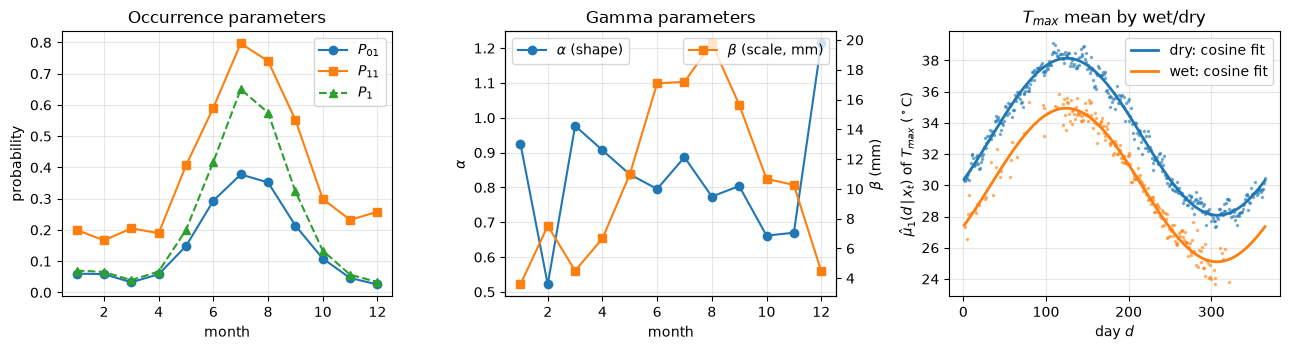

In [4]:
# --- precipitation: P01, P11 (Eq. 6.19), alpha, beta for each month ---
x_prev, x_cur, m_cur = x[:-1], x[1:], month[1:]
P01 = np.zeros(12); P11 = np.zeros(12); alpha = np.zeros(12); beta = np.zeros(12)
for m in range(1, 13):
    sel = m_cur == m
    P01[m-1] = ((x_prev==0)&(x_cur==1)&sel).sum() / ((x_prev==0)&sel).sum()   # dry days that have a next day
    P11[m-1] = ((x_prev==1)&(x_cur==1)&sel).sum() / ((x_prev==1)&sel).sum()
    amt_m = rain[(month==m) & (x==1)]
    beta[m-1] = amt_m.var(ddof=1) / amt_m.mean()          # beta = variance / mean
    alpha[m-1] = amt_m.mean() / beta[m-1]                 # alpha = mean / beta
P1 = P01 / (1 - P11 + P01)                                # Eq. 6.20

# --- weather variables: daily wet/dry mean and sd, cosine fit (Eq. 6.21) ---
OM = 0.0172
d_all = np.arange(1, 366)
def fit_cos(u, ok):
    """u_d = u_bar + C cos[0.0172 (d - T)] by least squares on the days where ok is True"""
    Xd = np.column_stack([np.ones(ok.sum()), np.cos(OM*d_all[ok]), np.sin(OM*d_all[ok])])
    c0, a, b = np.linalg.lstsq(Xd, u[ok], rcond=None)[0]
    return np.array([c0, np.hypot(a, b), np.arctan2(b, a)/OM])      # u_bar, C_amp, T_off
def cosine(p, d):
    return p[0] + p[1]*np.cos(OM*(d - p[2]))

mu_raw = np.full((S, 2, 365), np.nan); sd_raw = np.full((S, 2, 365), np.nan)
mu_fit = np.zeros((S, 2, 3)); sd_fit = np.zeros((S, 2, 3))
for s in range(S):
    for c in (0, 1):
        for d in d_all:
            v = z[s][(doy == d) & (x == c)]
            if len(v) >= 3:
                mu_raw[s, c, d-1], sd_raw[s, c, d-1] = v.mean(), v.std(ddof=1)
        ok = ~np.isnan(mu_raw[s, c])
        mu_fit[s, c] = fit_cos(mu_raw[s, c], ok); sd_fit[s, c] = fit_cos(sd_raw[s, c], ok)

# --- standardise (Eq. 6.22); the cosine value replaces any day with fewer than 3 wet days ---
y = np.zeros((S, n))
for s in range(S):
    for c in (0, 1):
        mu_d = np.where(np.isnan(mu_raw[s, c]), cosine(mu_fit[s, c], d_all), mu_raw[s, c])
        sd_d = np.where(np.isnan(sd_raw[s, c]), cosine(sd_fit[s, c], d_all), sd_raw[s, c])
        k = x == c
        y[s, k] = (z[s, k] - mu_d[doy[k]-1]) / sd_d[doy[k]-1]

# --- MAR(1): M0, M1 (Eq. 6.11), A1 (6.9), B from D = M0 - A1 M1^T (6.10) by Cholesky (6.12-6.16) ---
M0 = y[:, 1:] @ y[:, 1:].T / (n - 1)
M1 = y[:, 1:] @ y[:, :-1].T / (n - 1)
A1 = M1 @ np.linalg.inv(M0)
D = M0 - A1 @ M1.T
B = np.linalg.cholesky(D)
np.set_printoptions(precision=3, suppress=True)
print("M0 =\n", M0, "\nM1 =\n", M1, "\nA1 =\n", A1, "\nB =\n", B)
print("check B B^T = D:", np.allclose(B @ B.T, D))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
mo = np.arange(1, 13)
ax[0].plot(mo, P01, "o-", label="$P_{01}$"); ax[0].plot(mo, P11, "s-", label="$P_{11}$"); ax[0].plot(mo, P1, "^--", label="$P_1$")
ax[0].set(xlabel="month", ylabel="probability", title="Occurrence parameters"); ax[0].legend()
ax[1].plot(mo, alpha, "o-", label=r"$\alpha$ (shape)"); ax[1].set(xlabel="month", ylabel=r"$\alpha$", title="Gamma parameters")
ax1b = ax[1].twinx(); ax1b.plot(mo, beta, "s-", color="C1", label=r"$\beta$ (scale, mm)"); ax1b.set_ylabel(r"$\beta$ (mm)"); ax1b.grid(False)
ax[1].legend(loc="upper left"); ax1b.legend(loc="upper right")
for c, lab in ((0, "dry"), (1, "wet")):
    ax[2].plot(d_all, mu_raw[0, c], ".", ms=3, alpha=0.5, color=f"C{c}")
    ax[2].plot(d_all, cosine(mu_fit[0, c], d_all), "-", color=f"C{c}", lw=2, label=f"{lab}: cosine fit")
ax[2].set(xlabel="day $d$", ylabel=r"$\hat\mu_1(d\,|\,x_t)$ of $T_{max}$ ($^\circ$C)", title="$T_{max}$ mean by wet/dry"); ax[2].legend()
plt.tight_layout(); plt.show()

### 6.2.2 Simulation of weather variables

Now we roll the dice, day by day. Rain is simulated first, then the other variables given the simulated wet or dry state.

**Precipitation.** For each day look up the month's odds. Day 1 uses $P_1$; later days use $P_{01}$ if yesterday was dry and $P_{11}$ if it was wet; the day is wet when the random number $u$ is below that probability. On wet days draw a rain amount from the gamma distribution of that month.

**Weather variables.** (a) Run $\mathbf{Y}_t=\mathbf{A}_1\mathbf{Y}_{t-1}+\mathbf{B}\mathbf{E}_t$ (6.3) with random normal numbers $\mathbf{E}_t$ (the first day uses $\mathbf{Y}_1=\mathbf{B}\mathbf{E}_1$). (b) The $\mathbf{Y}$ values are standardised, so put the season back using the smooth waves for the simulated wet or dry state:

$$Z_t^s=\hat\mu_s(d|X_t)+\hat\sigma_s(d|X_t)\,Y_t^s\qquad(6.23)$$

(The book also allows a coefficient of variation instead of $\hat\sigma$, Eq. 6.24.) Below we generate 100 years and compare them with the 30-year record. Close agreement of the bars and lines is what we want.

*What this means for hydrology:* 100 years of consistent daily rain and temperature can drive a runoff or crop model to give risk estimates that 30 years cannot.

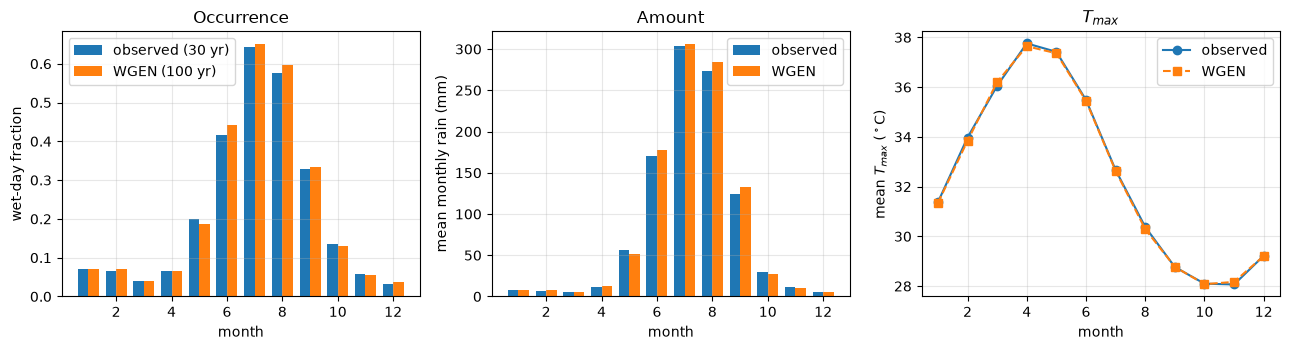

annual rain: observed 1007 mm, WGEN 1029 mm
corr(Tmax, Tmin): observed 0.59, WGEN 0.59


In [5]:
mon_of_day = np.repeat(np.arange(12), [31,28,31,30,31,30,31,31,30,31,30,31])   # month index (0-11) of each day of a year

def simulate_wgen(par, N_G, seed):
    """WGEN of Section 6.2.2: occurrence (Markov), amount (gamma), Tmax/Tmin/SR (MAR(1) + back-standardisation)."""
    rng = np.random.default_rng(seed)
    nn = N_G * 365
    d_sim, m_sim = np.tile(d_all, N_G), np.tile(mon_of_day, N_G)
    X_sim = np.zeros(nn, int); amt = np.zeros(nn)
    u = rng.random(nn)
    for t in range(nn):
        m = m_sim[t]
        p = par["P1"][m] if t == 0 else (par["P11"][m] if X_sim[t-1] else par["P01"][m])
        X_sim[t] = u[t] < p
        if X_sim[t]:
            amt[t] = rng.gamma(shape=par["alpha"][m], scale=par["beta"][m])
    E = rng.standard_normal((S, nn))
    Y = np.zeros((S, nn)); Y[:, 0] = par["B"] @ E[:, 0]
    for t in range(1, nn):
        Y[:, t] = par["A1"] @ Y[:, t-1] + par["B"] @ E[:, t]
    Z = np.zeros((S, nn))
    for s in range(S):
        for c in (0, 1):
            k = X_sim == c
            Z[s, k] = cosine(par["mu_fit"][s, c], d_sim[k]) + cosine(par["sd_fit"][s, c], d_sim[k]) * Y[s, k]
    return X_sim, amt, Z

par_O = dict(P01=P01, P11=P11, P1=P1, alpha=alpha, beta=beta, A1=A1, B=B, mu_fit=mu_fit, sd_fit=sd_fit)
N_G = 100
X_sim, amt, Z = simulate_wgen(par_O, N_G, seed=1)
m_sim = np.tile(mon_of_day + 1, N_G)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
w = 0.38
ax[0].bar(mo-w/2, [x[month==m].mean() for m in mo], w, label="observed (30 yr)")
ax[0].bar(mo+w/2, [X_sim[m_sim==m].mean() for m in mo], w, label="WGEN (100 yr)")
ax[0].set(xlabel="month", ylabel="wet-day fraction", title="Occurrence"); ax[0].legend()
ax[1].bar(mo-w/2, [rain[month==m].sum()/n_yr for m in mo], w, label="observed")
ax[1].bar(mo+w/2, [amt[m_sim==m].sum()/N_G for m in mo], w, label="WGEN")
ax[1].set(xlabel="month", ylabel="mean monthly rain (mm)", title="Amount"); ax[1].legend()
ax[2].plot(mo, [z[0][month==m].mean() for m in mo], "o-", label="observed")
ax[2].plot(mo, [Z[0][m_sim==m].mean() for m in mo], "s--", label="WGEN")
ax[2].set(xlabel="month", ylabel=r"mean $T_{max}$ ($^\circ$C)", title="$T_{max}$"); ax[2].legend()
plt.tight_layout(); plt.show()
print("annual rain: observed %.0f mm, WGEN %.0f mm" % (rain.sum()/n_yr, amt.sum()/N_G))
print("corr(Tmax, Tmin): observed %.2f, WGEN %.2f" % (np.corrcoef(z[0], z[1])[0,1], np.corrcoef(Z[0], Z[1])[0,1]))

### 6.2.3 Implementation of downscaling

Downscaling with WGEN means changing the model parameters (Wilby et al., 1998). Three parameter sets are used for each month: observation (O), the climate-model control run (C) and the model's future scenario (F). *Idea:* a climate model is better at changes than at daily weather, so we take its change (F relative to C) and apply it to the observed O.

**Occurrence.** The chain is described by the wet-day probability $P_1$ (6.20) and the lag-one autocorrelation $\gamma$, the day-to-day memory of wet/dry ($\gamma=0$ means yesterday tells nothing):

$$\gamma=P_{11}-P_{01}\qquad(6.25)$$

The adjusted wet-day probability uses the logit $\Psi(p)=\ln[p/(1-p)]$, the inverse of the logistic function $e^x/(1+e^x)$ (for example $\Psi(0.5)=0$, $\Psi(0.9)=2.2$):

$$P_1^{adj}=\Psi^{-1}\{\Psi(P_1^{O})+\Psi(P_1^{F})-\Psi(P_1^{C})\}\qquad(6.26)$$

and the correlation is adjusted with the Fisher z transform $\Theta(\gamma)=\tfrac12\ln[(1+\gamma)/(1-\gamma)]$, whose inverse is $\tanh$:

$$\gamma^{adj}=\Theta^{-1}\{\Theta(\gamma^{O})+\Theta(\gamma^{F})-\Theta(\gamma^{C})\}\qquad(6.27)$$

*Gloss:* both add the model's change on a scale with no limits and then map back, so the result stays a valid probability (between 0 and 1) or correlation (between $-1$ and $1$); adding the change directly to 0.95 could give 1.1. The key transition probabilities are then

$$P_{01}^{adj}=P_1^{adj}(1-\gamma^{adj})\quad(6.28),\qquad P_{11}^{adj}=\gamma^{adj}+P_{01}^{adj}\quad(6.29)$$

**Amount.** The gamma parameters are scaled by the future-to-control ratio:

$$\alpha^{adj}=\alpha^{O}\alpha^{F}/\alpha^{C}\quad(6.30),\qquad \beta^{adj}=\beta^{O}\beta^{F}/\beta^{C}\quad(6.31)$$

**Other weather variables.** Their daily averages are shifted and their standard deviations scaled, while $\mathbf{A}_1$ and $\mathbf{B}$ stay fixed:

$$\mu^{adj}=\mu^{O}+\mu^{F}-\mu^{C}\quad(6.32),\qquad \sigma^{adj}=\sigma^{O}\sigma^{F}/\sigma^{C}\quad(6.33)$$

The control and future values in the code are **illustrative numbers we chose**, not climate-model output: fewer wet starts, heavier rain on wet days, and warming of 2.5 C in $T_{max}$ and 2.0 C in $T_{min}$.

*For hydrology:* a coarse climate-model change becomes a long daily series at the station, including changes in how often it rains and how heavy the rain is.

July: P01 0.378 -> 0.300,  P11 0.797 -> 0.838,  P1 0.650 -> 0.649
annual rain: WGEN with O 1029 mm, adjusted WGEN 1266 mm
mean Tmax: 32.4 -> 34.9 C;  mean Tmin: 20.9 -> 22.9 C


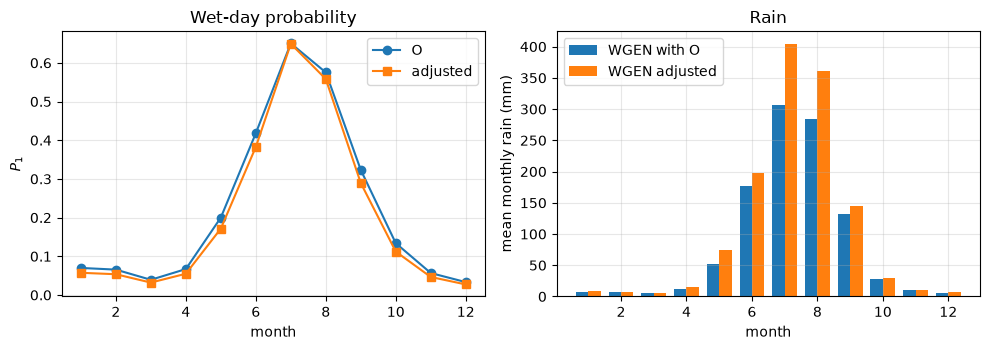

In [6]:
logit = lambda p: np.log(p / (1 - p))                   # Psi
expit = lambda v: 1 / (1 + np.exp(-v))                  # Psi^-1 (logistic function)
fisher_z = np.arctanh                                   # Theta(g) = 0.5 ln[(1+g)/(1-g)];  Theta^-1 = tanh

# illustrative control (C) and future (F) parameters, month by month
P01_C, P11_C, alpha_C, beta_C = P01*1.10, P11, alpha, beta*0.90
P01_F, P11_F, alpha_F, beta_F = P01_C*0.80, np.minimum(P11_C*1.05, 0.98), alpha_C, beta_C*1.35

P1_O, P1_C, P1_F = [p01/(1-p11+p01) for p01, p11 in ((P01, P11), (P01_C, P11_C), (P01_F, P11_F))]
gam_O, gam_C, gam_F = P11-P01, P11_C-P01_C, P11_F-P01_F
P1_adj  = expit(logit(P1_O) + logit(P1_F) - logit(P1_C))                          # Eq. 6.26
gam_adj = np.tanh(fisher_z(gam_O) + fisher_z(gam_F) - fisher_z(gam_C))            # Eq. 6.27
P01_adj = P1_adj * (1 - gam_adj)                                                  # Eq. 6.28
P11_adj = gam_adj + P01_adj                                                       # Eq. 6.29
alpha_adj = alpha * alpha_F / alpha_C                                             # Eq. 6.30
beta_adj  = beta * beta_F / beta_C                                                # Eq. 6.31

# Tmax, Tmin, SR: shift of the mean (6.32) and ratio of sd (6.33), applied to the fitted cosines
d_mu = np.array([2.5, 2.0, 0.0]);  r_sd = np.array([1.1, 1.0, 1.0])               # mu_F - mu_C, sigma_F / sigma_C
mu_adj, sd_adj = mu_fit.copy(), sd_fit.copy()
mu_adj[:, :, 0] += d_mu[:, None]                                                  # shifts u_bar only
sd_adj[:, :, :2] *= r_sd[:, None, None]                                           # scales u_bar and C

par_F = dict(P01=P01_adj, P11=P11_adj, P1=P01_adj/(1-P11_adj+P01_adj), alpha=alpha_adj, beta=beta_adj,
             A1=A1, B=B, mu_fit=mu_adj, sd_fit=sd_adj)
X_F, amt_F, Z_F = simulate_wgen(par_F, N_G, seed=2)

print("July: P01 %.3f -> %.3f,  P11 %.3f -> %.3f,  P1 %.3f -> %.3f" % (P01[6], P01_adj[6], P11[6], P11_adj[6], P1[6], par_F["P1"][6]))
print("annual rain: WGEN with O %.0f mm, adjusted WGEN %.0f mm" % (amt.sum()/N_G, amt_F.sum()/N_G))
print("mean Tmax: %.1f -> %.1f C;  mean Tmin: %.1f -> %.1f C" % (Z[0].mean(), Z_F[0].mean(), Z[1].mean(), Z_F[1].mean()))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(mo, P1, "o-", label="O"); ax[0].plot(mo, par_F["P1"], "s-", label="adjusted")
ax[0].set(xlabel="month", ylabel="$P_1$", title="Wet-day probability"); ax[0].legend()
ax[1].bar(mo-w/2, [amt[m_sim==m].sum()/N_G for m in mo], w, label="WGEN with O")
ax[1].bar(mo+w/2, [amt_F[m_sim==m].sum()/N_G for m in mo], w, label="WGEN adjusted")
ax[1].set(xlabel="month", ylabel="mean monthly rain (mm)", title="Rain"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6.3 Nonparametric weather generator

The nonparametric generator (NWG) uses no dice odds at all. It **reuses real days**. To get tomorrow, look at today's weather (Tmax, Tmin, SR, rain), find the observed days in other years at about the same time of year that were most similar to today, pick one of them at random, and copy the day that *followed* it. This is the "K-nearest-neighbour" idea (Yates et al., 2003; Sharif and Burn, 2006).

### 6.3.1 Simulation under current climate

The steps (the first day of the first generated year is drawn at random from the observed days of its window):

1. Candidates: all days within a window of width $b$ days around today's date, in all $n_{yr}$ years, $[(b+1)n_{yr}]-1$ in total.
2. Distance: for each candidate $\mathbf{x}_j$ compute the Mahalanobis distance to today's generated weather $\mathbf{X}_{ig,t}$,

   $$D_j=(\mathbf{X}_{ig,t}-\mathbf{x}_j)^T\,\mathbf{C}^{-1}\,(\mathbf{X}_{ig,t}-\mathbf{x}_j)\qquad(6.34)$$

   where $\mathbf{C}$ is the table of variances and covariances of the candidates. It is a squared difference in which a variable with a large spread (rain) counts for less than one with a small spread.
3. Keep the $K$ closest, with $K=\mathrm{Integer}\{[(b+1)n_{yr}-1]^{1/2}\}$.
4. Pick one of them with weights $w_m=(1/m)/\sum_{j=1}^{K}(1/j)$ ($m=1$ is the closest), so closer days are likelier, and copy the day after it.

Example weights for $K=5$: 0.44, 0.22, 0.15, 0.11, 0.09.

### 6.3.2 Simulation under future climate scenarios

Yates et al. (2003) bias the choice toward a subset of years, for example warmer or drier ones. The drawback is that a chosen size of change cannot be set.

*What this means for hydrology:* the generated weather is always physically realistic (it is real weather), but it can never produce a day more extreme than the record.

In [7]:
def knn_generate(data, doy_obs, n_days, b, seed):
    """K-nearest-neighbour resampling, Section 6.3.1. data[t, s]: observed S variables; returns n_days x S."""
    rng = np.random.default_rng(seed)
    n_obs, S_ = data.shape
    n_yr_ = n_obs // 365
    K = int(np.sqrt((b + 1) * n_yr_ - 1))                       # heuristic for K
    w_m = 1 / np.arange(1, K + 1); w_m /= w_m.sum(); cw = np.cumsum(w_m)      # weights w_m and their cumulative sum
    cand, Cinv = {}, {}
    for d in range(365):                                        # candidate days and C^-1 for each day of the year
        dist = np.abs(((doy_obs - 1 - d + 182) % 365) - 182)    # circular distance in days
        idx = np.where((dist <= b // 2) & (np.arange(n_obs) < n_obs - 1))[0]   # candidate must have a following day
        cand[d] = idx; Cinv[d] = np.linalg.inv(np.cov(data[idx].T))
    out = np.zeros((n_days, S_))
    out[0] = data[rng.choice(cand[0])]                          # first day: random observed day of the window
    for t in range(1, n_days):
        d = t % 365
        diff = out[t-1] - data[cand[d]]
        D_j = np.einsum("ij,jk,ik->i", diff, Cinv[d], diff)     # Eq. 6.34
        nearest = cand[d][np.argsort(D_j)[:K]]
        pick = nearest[min(np.searchsorted(cw, rng.random()), K - 1)]
        out[t] = data[pick + 1]                                 # values of the day that FOLLOWS the chosen day
    return out, K

data = np.column_stack([z[0], z[1], z[2], rain])                # Tmax, Tmin, SR, rain
sim_knn, K = knn_generate(data, doy, 30 * 365, b=14, seed=3)
print("b = 14, n_yr = 30: K =", K, "; weights w_m for K = 5:", np.round((1/np.arange(1,6))/np.sum(1/np.arange(1,6)), 2))
print("small case b = 4, n_yr = 10: K =", int(np.sqrt((4+1)*10 - 1)))
print("                  observed     NWG")
for name, k in (("Tmax (C)", 0), ("Tmin (C)", 1), ("SR", 2)):
    print(f"mean {name:9s} {data[:, k].mean():9.2f} {sim_knn[:, k].mean():8.2f}")
print(f"annual rain (mm) {rain.sum()/30:9.0f} {sim_knn[:, 3].sum()/30:8.0f}")
print(f"wet-day fraction {(rain>=0.1).mean():9.3f} {(sim_knn[:, 3]>=0.1).mean():8.3f}")

b = 14, n_yr = 30: K = 21 ; weights w_m for K = 5: [0.44 0.22 0.15 0.11 0.09]
small case b = 4, n_yr = 10: K = 7
                  observed     NWG
mean Tmax (C)      32.42    32.34
mean Tmin (C)      20.87    20.79
mean SR            16.82    16.87
annual rain (mm)      1007     1002
wet-day fraction     0.221    0.221


## 6.4 Summary and conclusion

- A weather generator rolls dice whose odds are fitted to the record: Markov chain for wet/dry, gamma for rain amount, MAR(1) for Tmax, Tmin and SR.
- The odds of rain come from counting: $P_{01}$ and $P_{11}$, with divisors that count only days that have a following day; the long-run wet share is $P_1=P_{01}/(1-P_{11}+P_{01})$.
- Temperature and radiation are standardised for season and wet/dry state, then modelled by MAR(1) with $\mathbf{A}_1$ and $\mathbf{B}$.
- Downscaling changes the odds: logit for $P_1$, Fisher z for $\gamma$, ratios for $\alpha$, $\beta$, $\sigma$, differences for the averages.
- The nearest-neighbour generator copies the day after one of the $K$ most similar observed days.

## Check your understanding

1. In the hand example, why is the dry divisor 11 and not 12? What would the wet divisor be if day 20 were wet?
2. Why are changes added on the logit scale and not directly to $P_1$?
3. Why are temperature and radiation standardised before fitting the MAR(1)?

## Try it yourself

- Change the three uniform numbers in the hand example so that the simulated days are wet, wet, dry. Which $u$ ranges give that?
- Change `d_mu` and `r_sd` in Section 4 and see how the simulated mean $T_{max}$ responds.
- Run `knn_generate` with $b=4$ and $b=30$ and compare the simulated wet-day fraction.

```{note} Where this lecture differs from the book
- **Eq. (6.19) divisors and Example 6.1.** The book divides by $N_1-1$ for $P_{11}$ and by $N_0$ for $P_{01}$. The correct divisor is the number of days in the starting state that *have a following day*: $N_1-1$ only if the record ends on a wet day, $N_0-1$ only if it ends dry. The book's July record ends dry, so its $P_{11}$ should use $N_1$ and $P_{01}$ should use $N_0-1$.
- **Eq. (6.6).** The printed $\mathbf{M}_0=\mathbf{A}_1\mathbf{M}_1+\mathbf{B}\mathbf{B}^T$ lacks the transpose; $\mathbf{M}_1^T$ is what Eq. (6.10) requires. The extracted text of Eq. (6.3) dropped $\mathbf{B}$; read from the page image it is $\mathbf{Y}_t=\mathbf{A}_1\mathbf{Y}_{t-1}+\mathbf{B}\mathbf{E}_t$.
- **Eq. (6.26).** The text names $\Psi$ both the logistic function and its inverse; we use $\Psi$ = logit throughout, as the book's Example 6.5 does numerically.
- **Example 6.6.** The heuristic gives $K=\mathrm{Integer}\{[(b+1)n_{yr}-1]^{1/2}\}=7$ for $b=4$, $n_{yr}=10$; the book prints 15 and then uses 5. The weight rule cites Eq. (8.2); it is the $w_m$ given in step 6 here. Distances in (6.34) are squared (no root), as in the book's numbers.
```

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The method follows Lee, T., & Singh, V. P. (2019), *Statistical Downscaling for Hydrological and Environmental Applications*, CRC Press, **Chapter 6** (6.1 mathematical background, 6.2 weather generator: 6.2.1 fitting, 6.2.2 simulation, 6.2.3 implementation of downscaling, 6.3 nonparametric weather generator). The explanations, the synthetic data, the code and the figures are our own; the numerical examples of the book are not reproduced.

**Method papers.** Richardson, C. W., & Wright, D. A. (1984). *WGEN: A model for generating daily weather variables*. USDA-ARS, ARS-8. &middot; Matalas, N. C. (1967). *Water Resources Research, 3*(4), 937&ndash;945. &middot; Wilby, R. L., et al. (1998). *Journal of Hydrology, 205*, 1&ndash;19. &middot; Lall, U., & Sharma, A. (1996). *Water Resources Research, 32*(3), 679&ndash;691. &middot; Yates, D., et al. (2003). *Water Resources Research, 39*(7), 1199. &middot; Sharif, M., & Burn, D. H. (2006). *Journal of Hydrologic Engineering, 11*(1), 42&ndash;49.

**Data.** `data/downscaling/lec21/obs_daily_synthetic.csv` is **synthetic**, made for this lecture; it does not describe any station. The workbook `lec21_worked_examples.xlsx` holds the hand example and its simulation. The control and future parameters in Section 4 are illustrative, not projections.
```